# B5 – K-Means Clustering

**Problem:** Apply K-Means clustering to `sales_data_sample.csv` and determine the number of clusters using the Elbow Method.

**Before running:** Keep `sales_data_sample.csv` in the same folder as this notebook.

## 1. Import Libraries

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

## 2. Load Dataset

In [9]:
df = pd.read_csv('sales_data_sample.csv', encoding='latin1')
print(df.head())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

## 3. Select Features and Scale Data

Use two relevant numerical features: quantity ordered and sales. Scaling is important because K-Means uses distance to form clusters.

In [10]:
X = df[['QUANTITYORDERED', 'SALES']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 4. Find the Number of Clusters Using the Elbow Method

The Elbow Method plots WCSS for different values of K. Select K near the point where the curve starts flattening.

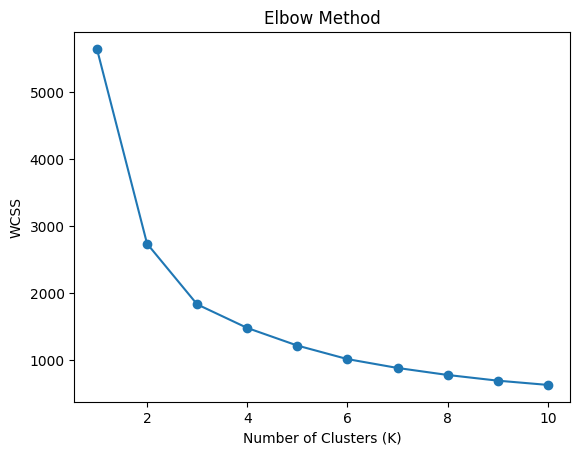

In [11]:
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

**Select K from the graph:** The elbow is the point after which adding more clusters reduces WCSS more slowly. The value `3` below is a starting choice; change it if your graph shows a different elbow.

## 5. Apply K-Means Clustering

In [12]:
k = 3

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

df['Cluster'] = clusters
print(df[['QUANTITYORDERED', 'SALES', 'Cluster']].head(10))

   QUANTITYORDERED    SALES  Cluster
0               30  2871.00        1
1               34  2765.90        0
2               41  3884.34        0
3               45  3746.70        0
4               49  5205.27        2
5               36  3479.76        0
6               29  2497.77        1
7               48  5512.32        2
8               22  2168.54        1
9               41  4708.44        0


## 6. Visualize Clusters

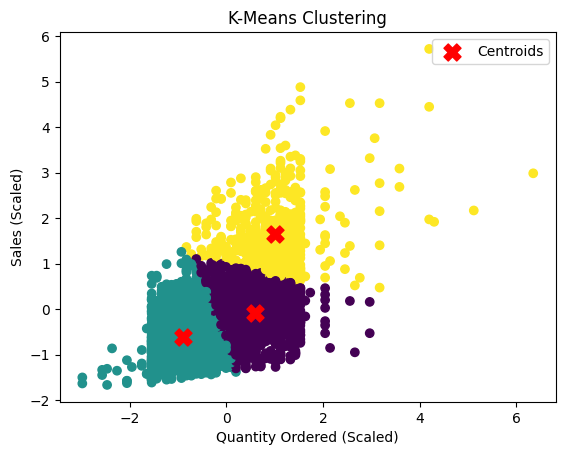

In [13]:
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=clusters, cmap='viridis')
plt.scatter(kmeans.cluster_centers_[:, 0],
            kmeans.cluster_centers_[:, 1],
            color='red', marker='X', s=150, label='Centroids')

plt.xlabel('Quantity Ordered (Scaled)')
plt.ylabel('Sales (Scaled)')
plt.title('K-Means Clustering')
plt.legend()
plt.show()

## 7. Display Cluster Counts

In [14]:
print(df['Cluster'].value_counts().sort_index())

0    1043
1    1260
2     520
Name: Cluster, dtype: int64


## Conclusion

K-Means clustering was applied to the sales dataset using quantity ordered and sales. The Elbow Method was used to choose the number of clusters, and the final clusters were displayed in a scatter plot.

## Short Viva Points

1. **K-Means:** An unsupervised algorithm that groups similar data points into K clusters.
2. **Centroid:** The center (mean position) of a cluster.
3. **Elbow Method:** A graph-based method for choosing K using WCSS.
4. **WCSS:** Sum of squared distances between data points and their assigned cluster centers.
5. **Why scale data?** So a feature with larger values does not dominate distance calculations.